# Analyse et modèles prédictifs Spotify

Ce notebook réunit la préparation des données, l’exploration, la régression et la classification. Il s’exécute de haut en bas depuis la racine du projet.

Les variables sont nommées de façon cohérente : `raw_tracks` pour les données chargées, `tracks` pour le jeu nettoyé, puis des noms préfixés par `regression_`, `classification_` ou `popularity_` pour chaque tâche.

## 1. Imports et configuration

Le notebook lit d’abord `data/spotify_clean.csv` s’il existe. Sinon, il télécharge le CSV source. Le jeu nettoyé est ensuite sauvegardé au même emplacement.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path("data/spotify_clean.csv")
SPOTIFY_URL = (
    "https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
    "master/data/2020/2020-01-21/spotify_songs.csv"
)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 2. Chargement et préparation des données

In [2]:
if DATA_PATH.exists():
    raw_tracks = pd.read_csv(DATA_PATH)
    print(f"Fichier local chargé : {DATA_PATH}")
else:
    raw_tracks = pd.read_csv(SPOTIFY_URL)
    print("Fichier source Spotify téléchargé.")

print(f"Dimensions avant nettoyage : {raw_tracks.shape}")
display(raw_tracks.dtypes.to_frame("type"))
display(
    raw_tracks.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("valeurs_manquantes")
)

Fichier local chargé : data\spotify_clean.csv
Dimensions avant nettoyage : (28356, 24)


,type
track_id,str
track_name,str
track_artist,str
track_popularity,int64
track_album_id,str
track_album_name,str
track_album_release_date,str
playlist_name,str
playlist_id,str
playlist_genre,str


,valeurs_manquantes
track_name,4
track_artist,4
track_album_name,4
track_id,0
track_popularity,0
track_album_id,0
track_album_release_date,0
playlist_name,0
playlist_id,0
playlist_genre,0


In [3]:
tracks = raw_tracks.drop_duplicates(subset="track_id", keep="first").copy()
tracks["release_year"] = pd.to_numeric(
    tracks["track_album_release_date"]
    .astype("string")
    .str.extract(r"(\d{4})", expand=False),
    errors="coerce",
).astype("Int64")
tracks["duration_min"] = tracks["duration_ms"] / 60_000
tracks = tracks.loc[tracks["duration_min"].between(2.0, 4.5)].copy()
tracks["playlist_genre"] = tracks["playlist_genre"].astype("category")

DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
tracks.to_csv(DATA_PATH, index=False)
print(f"Dimensions après déduplication et filtre de durée : {tracks.shape}")
print(f"Titres associés à plusieurs genres : "
      f"{(tracks.groupby('track_id')['playlist_genre'].nunique() > 1).sum()}")
display(tracks.head())

Dimensions après déduplication et filtre de durée : (22609, 25)
Titres associés à plusieurs genres : 0


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,duration_min,release_year
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,3.245900,2019
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,2.710000,2019
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,2.943600,2019
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093,2.818217,2019
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052,3.150867,2019


## 3. Exploration des données

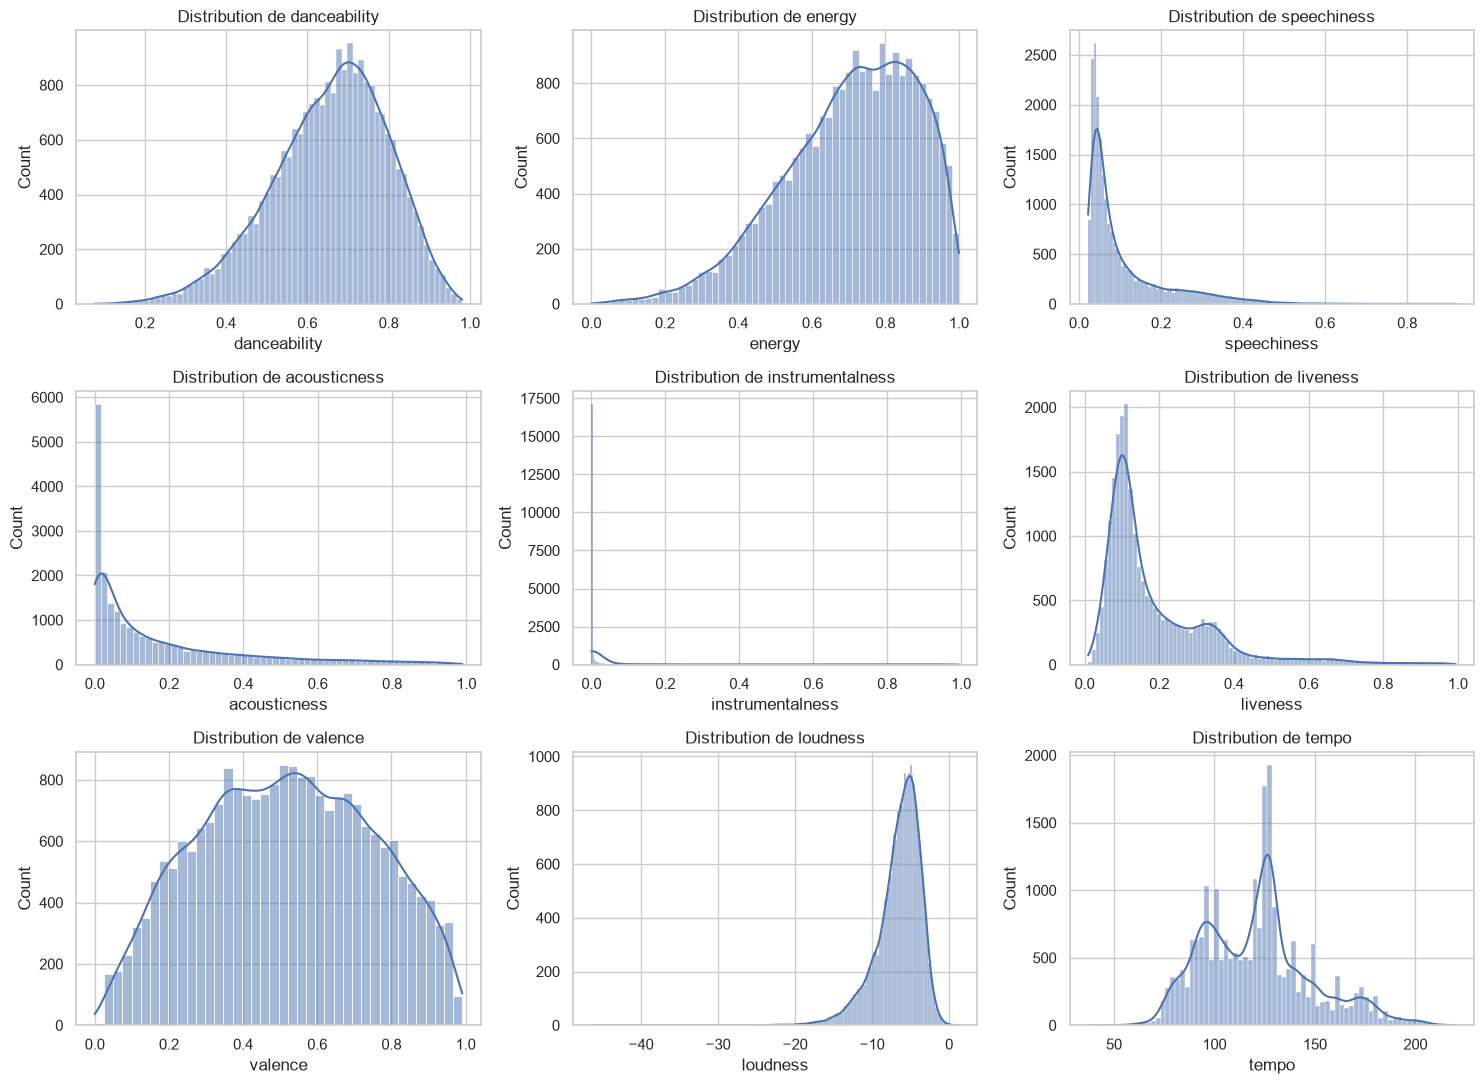

In [4]:
audio_features = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "loudness",
    "tempo",
]

figure, axes = plt.subplots(3, 3, figsize=(15, 11))
for feature, axis in zip(audio_features, axes.flat):
    sns.histplot(data=tracks, x=feature, kde=True, ax=axis)
    axis.set_title(f"Distribution de {feature}")
plt.tight_layout()
plt.show()

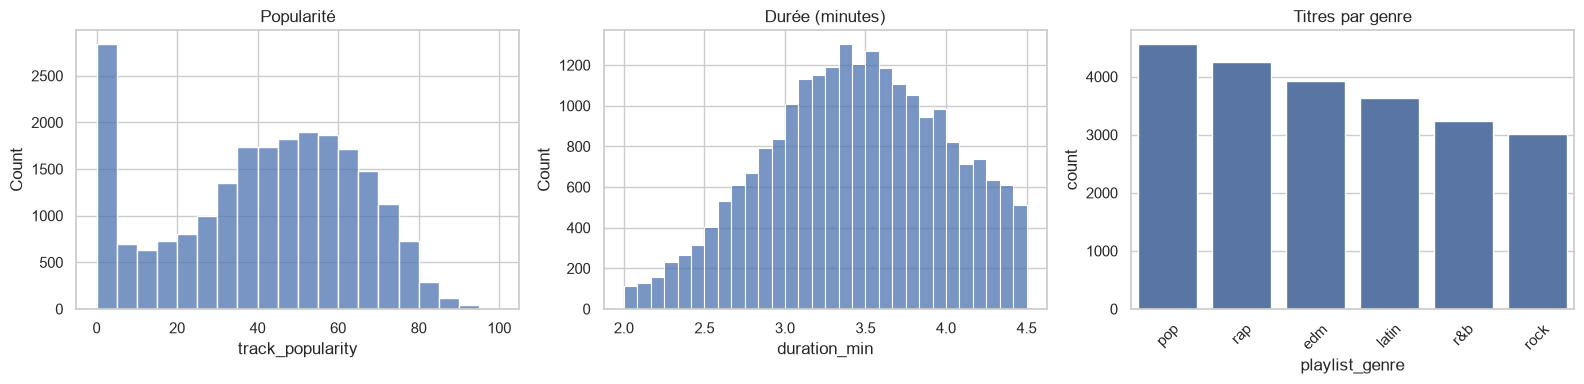

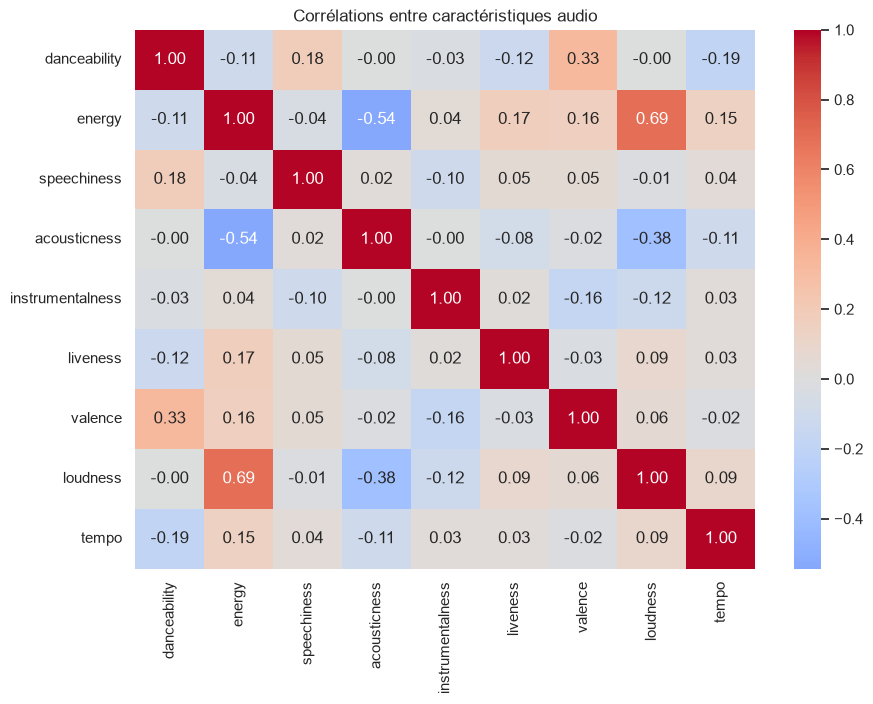

,correlation_avec_energy
loudness,0.691625
acousticness,-0.543824
liveness,0.171704
valence,0.156984
tempo,0.146304
danceability,-0.107918
instrumentalness,0.044076
speechiness,-0.040955


In [5]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=tracks, x="track_popularity", bins=20, ax=axes[0])
axes[0].set_title("Popularité")
sns.histplot(data=tracks, x="duration_min", bins=30, ax=axes[1])
axes[1].set_title("Durée (minutes)")
sns.countplot(
    data=tracks,
    x="playlist_genre",
    order=tracks["playlist_genre"].value_counts().index,
    ax=axes[2],
)
axes[2].tick_params(axis="x", rotation=45)
axes[2].set_title("Titres par genre")
plt.tight_layout()
plt.show()

audio_correlations = tracks[audio_features].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(
    audio_correlations, annot=True, cmap="coolwarm", center=0, fmt=".2f"
)
plt.title("Corrélations entre caractéristiques audio")
plt.show()
display(
    audio_correlations["energy"]
    .drop("energy")
    .sort_values(key=abs, ascending=False)
    .to_frame("correlation_avec_energy")
)

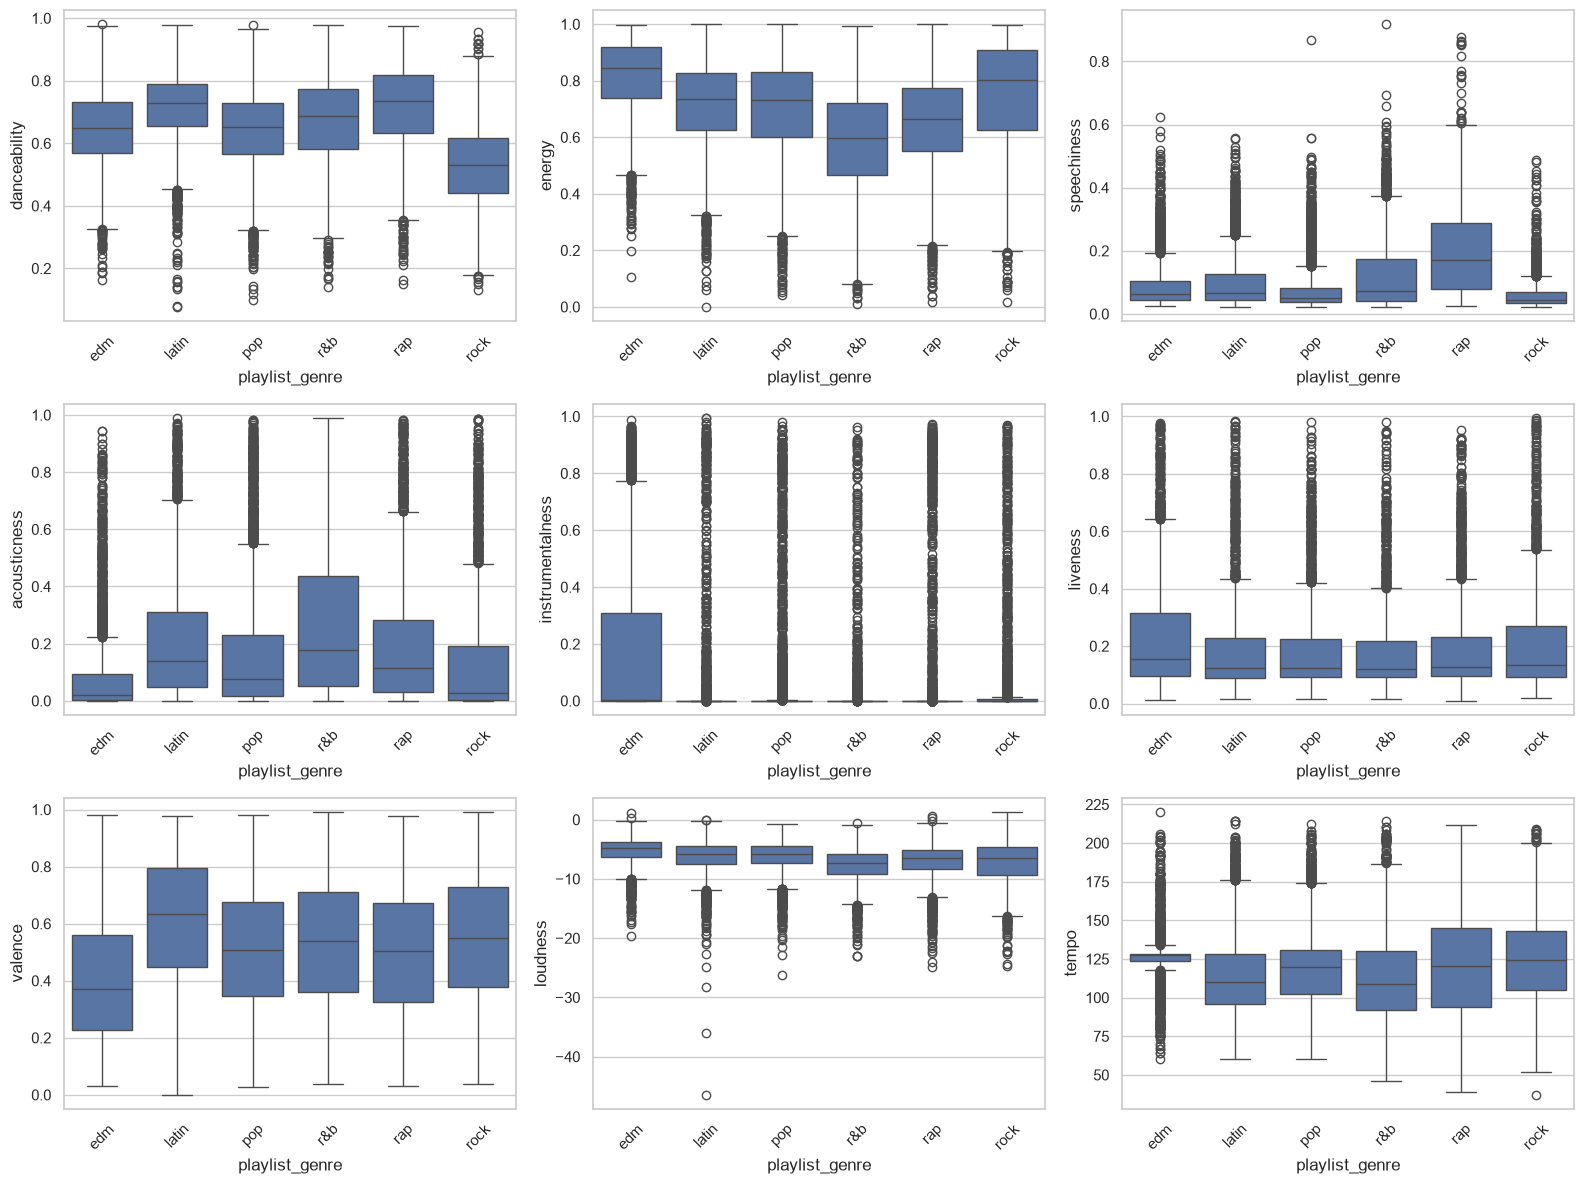

,popularite_moyenne
playlist_genre,
pop,46.960368
rap,42.840989
latin,42.290794
rock,40.644636
r&b,37.454461
edm,33.121715


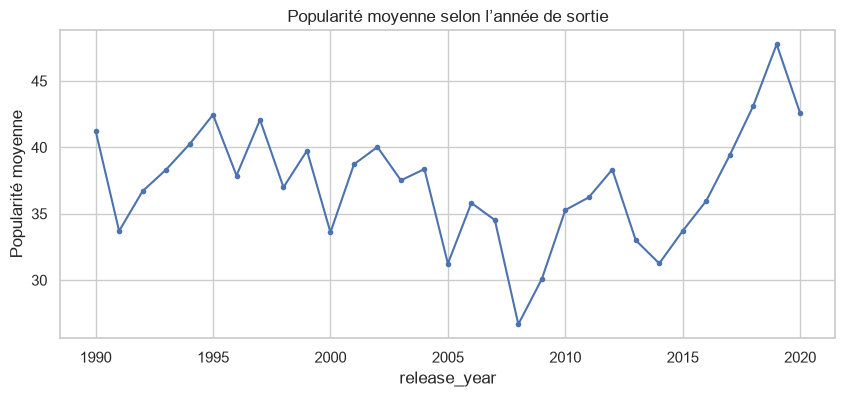

In [6]:
figure, axes = plt.subplots(3, 3, figsize=(16, 12))
for feature, axis in zip(audio_features, axes.flat):
    sns.boxplot(data=tracks, x="playlist_genre", y=feature, ax=axis)
    axis.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

display(
    tracks.groupby("playlist_genre", observed=True)["track_popularity"]
    .mean()
    .sort_values(ascending=False)
    .to_frame("popularite_moyenne")
)
popularity_by_year = (
    tracks.dropna(subset=["release_year"])
    .groupby("release_year", observed=True)["track_popularity"]
    .mean()
)
popularity_by_year = popularity_by_year.loc[
    (popularity_by_year.index >= 1990)
    & (popularity_by_year.index <= 2020)
]
popularity_by_year.plot(figsize=(10, 4), marker=".")
plt.title("Popularité moyenne selon l’année de sortie")
plt.ylabel("Popularité moyenne")
plt.show()

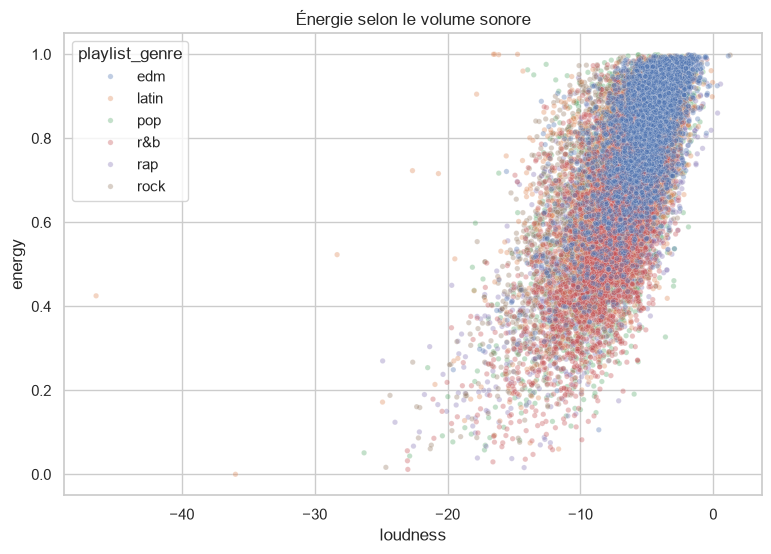

Top 10 artistes :


,nombre_titres
track_artist,
Queen,92
David Guetta,72
Martin Garrix,71
Don Omar,71
The Chainsmokers,65
Hardwell,59
Drake,56
Dimitri Vegas & Like Mike,51
Logic,50


Top 10 titres les plus populaires :


,track_name,track_artist,track_popularity,playlist_genre
1504,Dance Monkey,Tones and I,100,pop
18031,ROXANNE,Arizona Zervas,99,latin
687,Tusa,KAROL G,98,pop
711,Memories,Maroon 5,98,pop
716,Blinding Lights,The Weeknd,98,pop
1299,Circles,Post Malone,98,pop
5133,The Box,Roddy Ricch,98,rap
689,everything i wanted,Billie Eilish,97,pop
1300,Don't Start Now,Dua Lipa,97,pop
2941,Falling,Trevor Daniel,97,pop


In [7]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tracks,
    x="loudness",
    y="energy",
    hue="playlist_genre",
    alpha=0.35,
    s=15,
)
plt.title("Énergie selon le volume sonore")
plt.show()

print("Top 10 artistes :")
display(tracks["track_artist"].value_counts().head(10).to_frame("nombre_titres"))
print("Top 10 titres les plus populaires :")
display(
    tracks.nlargest(10, "track_popularity")[
        ["track_name", "track_artist", "track_popularity", "playlist_genre"]
    ]
)

## 4. Régression : prédire l’énergie

Le jeu de test est mis de côté avant de choisir la variable du modèle simple. Les variables catégorielles sont encodées à partir du train, puis les colonnes du test sont alignées sur celles du train.

In [8]:
regression_numeric_features = [
    "danceability",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "loudness",
    "tempo",
    "duration_min",
    "key",
    "mode",
]
regression_categorical_features = ["playlist_genre", "playlist_subgenre"]
regression_data = tracks.dropna(
    subset=regression_numeric_features
    + regression_categorical_features
    + ["energy"]
).copy()
regression_train_index, regression_test_index = train_test_split(
    regression_data.index, test_size=0.2, random_state=RANDOM_STATE
)
regression_y_train = regression_data.loc[regression_train_index, "energy"]
regression_y_test = regression_data.loc[regression_test_index, "energy"]

training_correlations = regression_data.loc[
    regression_train_index, regression_numeric_features + ["energy"]
].corr(numeric_only=True)["energy"].drop("energy")
simple_regression_feature = training_correlations.abs().idxmax()
print(
    "Variable la plus corrélée à energy (train) : "
    f"{simple_regression_feature} "
    f"({training_correlations[simple_regression_feature]:.3f})"
)

regression_x_simple_train = regression_data.loc[
    regression_train_index, [simple_regression_feature]
]
regression_x_simple_test = regression_data.loc[
    regression_test_index, [simple_regression_feature]
]
regression_x_numeric_train = regression_data.loc[
    regression_train_index, regression_numeric_features
]
regression_x_numeric_test = regression_data.loc[
    regression_test_index, regression_numeric_features
]

regression_training_frame = regression_data.loc[
    regression_train_index,
    regression_numeric_features + regression_categorical_features,
]
regression_test_frame = regression_data.loc[
    regression_test_index,
    regression_numeric_features + regression_categorical_features,
]
regression_x_categorical_train = pd.get_dummies(
    regression_training_frame,
    columns=regression_categorical_features,
    drop_first=True,
    dtype=int,
)
regression_x_categorical_test = pd.get_dummies(
    regression_test_frame,
    columns=regression_categorical_features,
    drop_first=True,
    dtype=int,
).reindex(columns=regression_x_categorical_train.columns, fill_value=0)

def evaluate_regression(name, estimator, x_train, x_test, y_train, y_test):
    estimator.fit(x_train, y_train)
    train_predictions = estimator.predict(x_train)
    test_predictions = estimator.predict(x_test)
    return {
        "model": name,
        "estimator": estimator,
        "feature_columns": list(x_train.columns),
        "r2_train": r2_score(y_train, train_predictions),
        "r2_test": r2_score(y_test, test_predictions),
        "mae_train": mean_absolute_error(y_train, train_predictions),
        "mae_test": mean_absolute_error(y_test, test_predictions),
        "rmse_train": np.sqrt(mean_squared_error(y_train, train_predictions)),
        "rmse_test": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "test_predictions": test_predictions,
    }

Variable la plus corrélée à energy (train) : loudness (0.690)


In [9]:
top_four_features = ["loudness", "acousticness", "valence", "danceability"]
regression_x_top_four_train = regression_data.loc[
    regression_train_index, top_four_features
]
regression_x_top_four_test = regression_data.loc[
    regression_test_index, top_four_features
]

regression_results = [
    evaluate_regression(
        "Linéaire simple",
        LinearRegression(),
        regression_x_simple_train,
        regression_x_simple_test,
        regression_y_train,
        regression_y_test,
    ),
    evaluate_regression(
        "Linéaire numérique",
        LinearRegression(),
        regression_x_numeric_train,
        regression_x_numeric_test,
        regression_y_train,
        regression_y_test,
    ),
    evaluate_regression(
        "Linéaire + catégories",
        LinearRegression(),
        regression_x_categorical_train,
        regression_x_categorical_test,
        regression_y_train,
        regression_y_test,
    ),
    evaluate_regression(
        "Forêt aléatoire",
        RandomForestRegressor(
            n_estimators=150,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        regression_x_numeric_train,
        regression_x_numeric_test,
        regression_y_train,
        regression_y_test,
    ),
    evaluate_regression(
        "Linéaire (Top 4)",
        LinearRegression(),
        regression_x_top_four_train,
        regression_x_top_four_test,
        regression_y_train,
        regression_y_test,
    ),
]
regression_comparison = (
    pd.DataFrame(
        [
            {key: value for key, value in result.items()
             if key not in {"estimator", "feature_columns", "test_predictions"}}
            for result in regression_results
        ]
    )
    .sort_values("r2_test", ascending=False)
    .reset_index(drop=True)
)
display(regression_comparison)

,model,r2_train,r2_test,mae_train,mae_test,rmse_train,rmse_test
0,Forêt aléatoire,0.944380,0.724786,0.031022,0.073310,0.042240,0.095238
1,Linéaire + catégories,0.669138,0.669191,0.080710,0.081144,0.103022,0.104415
2,Linéaire numérique,0.632794,0.635013,0.085568,0.085837,0.108533,0.109677
3,Linéaire (Top 4),0.606293,0.613261,0.089144,0.088637,0.112381,0.112898
4,Linéaire simple,0.475887,0.487846,0.103049,0.101975,0.129664,0.129920


Coefficients du modèle linéaire numérique :


,coefficient
acousticness,-0.254753
danceability,-0.190380
valence,0.150548
instrumentalness,0.117514
liveness,0.097250
loudness,0.035446
duration_min,0.003737
mode,-0.001945
speechiness,0.000897
key,0.000262


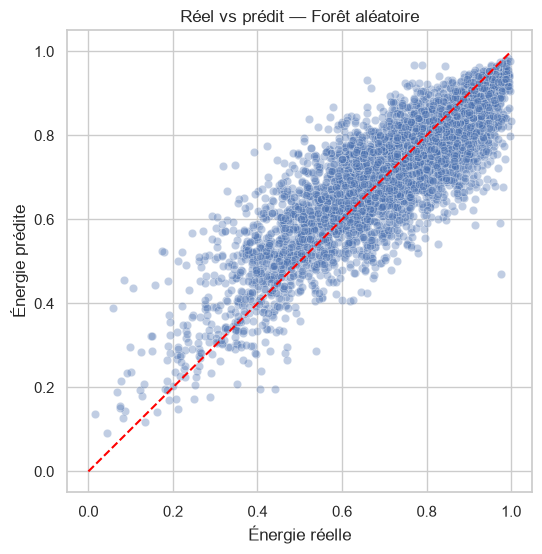

Modèle exportable pour l’application : Forêt aléatoire


In [10]:
best_regression_result = max(
    regression_results, key=lambda result: result["r2_test"]
)
numeric_regression_results = [
    result
    for result in regression_results
    if result["feature_columns"] == regression_numeric_features
]
best_deployable_regression = max(
    numeric_regression_results, key=lambda result: result["r2_test"]
)
best_linear_numeric_regression = next(
    result
    for result in regression_results
    if result["model"] == "Linéaire numérique"
)

regression_coefficients = pd.Series(
    best_linear_numeric_regression["estimator"].coef_,
    index=regression_numeric_features,
)
print("Coefficients du modèle linéaire numérique :")
display(
    regression_coefficients
    .reindex(regression_coefficients.abs().sort_values(ascending=False).index)
    .to_frame("coefficient")
)

plt.figure(figsize=(6, 6))
sns.scatterplot(
    x=regression_y_test,
    y=best_regression_result["test_predictions"],
    alpha=0.35,
)
plt.plot([0, 1], [0, 1], color="red", linestyle="--")
plt.xlabel("Énergie réelle")
plt.ylabel("Énergie prédite")
plt.title(f"Réel vs prédit — {best_regression_result['model']}")
plt.show()

print(
    "Modèle exportable pour l’application : "
    f"{best_deployable_regression['model']}"
)

In [11]:
popularity_regression_data = tracks.dropna(
    subset=regression_numeric_features + ["track_popularity"]
)
popularity_regression_train_index, popularity_regression_test_index = (
    train_test_split(
        popularity_regression_data.index,
        test_size=0.2,
        random_state=RANDOM_STATE,
    )
)
popularity_regression_result = evaluate_regression(
    "Popularité — forêt aléatoire",
    RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    popularity_regression_data.loc[
        popularity_regression_train_index, regression_numeric_features
    ],
    popularity_regression_data.loc[
        popularity_regression_test_index, regression_numeric_features
    ],
    popularity_regression_data.loc[
        popularity_regression_train_index, "track_popularity"
    ],
    popularity_regression_data.loc[
        popularity_regression_test_index, "track_popularity"
    ],
)
display(
    pd.DataFrame(
        [
            {
                key: value
                for key, value in popularity_regression_result.items()
                if key not in {"estimator", "feature_columns", "test_predictions"}
            }
        ]
    )
)

,model,r2_train,r2_test,mae_train,mae_test,rmse_train,rmse_test
0,Popularité — forêt aléatoire,0.799196,0.015027,8.363185,18.851706,10.521055,22.984711


## 5. Classification : prédire le genre musical

La sélection du modèle repose sur le F1 macro en validation croisée, uniquement sur le train. Le jeu de test ne sert qu’à l’évaluation finale.

In [12]:
classification_features = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "loudness",
    "tempo",
    "duration_min",
    "key",
    "mode",
    "release_year",
]
classification_data = tracks.dropna(
    subset=classification_features + ["playlist_genre"]
).copy()
classification_x = classification_data[classification_features]
classification_y = classification_data["playlist_genre"].astype(str)
(
    classification_x_train,
    classification_x_test,
    classification_y_train,
    classification_y_test,
) = train_test_split(
    classification_x,
    classification_y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=classification_y,
)
print(f"Dimensions train : {classification_x_train.shape}")
print(f"Dimensions test : {classification_x_test.shape}")
print(f"Genres : {sorted(classification_y.unique())}")

majority_genre = classification_y_train.mode().iloc[0]
majority_predictions = np.full(
    len(classification_y_test), majority_genre
)
print(
    "Accuracy de la classe majoritaire : "
    f"{accuracy_score(classification_y_test, majority_predictions):.3f}"
)
print(
    "Accuracy théorique du hasard uniforme : "
    f"{1 / classification_y.nunique():.3f}"
)

knn_values = [1, 5, 15, 31]
classification_models = {
    "Régression logistique": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=3000)
    ),
    **{
        f"KNN (k={neighbors})": make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=neighbors),
        )
        for neighbors in knn_values
    },
    "Forêt aléatoire": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

Dimensions train : (18087, 13)
Dimensions test : (4522, 13)
Genres : ['edm', 'latin', 'pop', 'r&b', 'rap', 'rock']
Accuracy de la classe majoritaire : 0.202
Accuracy théorique du hasard uniforme : 0.167


In [13]:
classification_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
classification_cv_f1 = {}
for model_name, estimator in classification_models.items():
    fold_scores = cross_val_score(
        estimator,
        classification_x_train,
        classification_y_train,
        scoring="f1_macro",
        cv=classification_cv,
        n_jobs=-1,
    )
    classification_cv_f1[model_name] = fold_scores.mean()

classification_results = []
classification_predictions = {}
classification_confusion_matrices = {}
genre_labels = np.sort(classification_y.unique())
for model_name, estimator in classification_models.items():
    estimator.fit(classification_x_train, classification_y_train)
    train_predictions = estimator.predict(classification_x_train)
    test_predictions = estimator.predict(classification_x_test)
    classification_predictions[model_name] = test_predictions
    classification_confusion_matrices[model_name] = confusion_matrix(
        classification_y_test, test_predictions, labels=genre_labels
    )
    classification_results.append(
        {
            "model": model_name,
            "f1_macro_cv": classification_cv_f1[model_name],
            "accuracy_train": accuracy_score(
                classification_y_train, train_predictions
            ),
            "accuracy_test": accuracy_score(
                classification_y_test, test_predictions
            ),
            "precision_macro": precision_score(
                classification_y_test,
                test_predictions,
                average="macro",
                zero_division=0,
            ),
            "recall_macro": recall_score(
                classification_y_test,
                test_predictions,
                average="macro",
                zero_division=0,
            ),
            "f1_macro_test": f1_score(
                classification_y_test,
                test_predictions,
                average="macro",
                zero_division=0,
            ),
        }
    )

classification_comparison = (
    pd.DataFrame(classification_results)
    .sort_values("f1_macro_cv", ascending=False)
    .reset_index(drop=True)
)
display(classification_comparison.style.format(
    {column: "{:.3f}" for column in classification_comparison.columns
     if column != "model"}
))

,model,f1_macro_cv,accuracy_train,accuracy_test,precision_macro,recall_macro,f1_macro_test
0,Forêt aléatoire,0.577,0.986,0.575,0.580,0.575,0.572
1,KNN (k=31),0.502,0.540,0.499,0.512,0.495,0.497
2,KNN (k=15),0.492,0.562,0.492,0.505,0.490,0.493
3,Régression logistique,0.479,0.481,0.477,0.477,0.476,0.473
4,KNN (k=5),0.459,0.622,0.468,0.483,0.469,0.471
5,KNN (k=1),0.430,0.994,0.431,0.439,0.434,0.436


Modèle retenu : Forêt aléatoire
F1 macro CV : 0.577
Accuracy test : 0.575
F1 macro test : 0.572
              precision    recall  f1-score   support

         edm       0.66      0.70      0.68       784
       latin       0.54      0.41      0.47       726
         pop       0.46      0.51      0.48       913
         r&b       0.52      0.35      0.42       648
         rap       0.56      0.69      0.62       849
        rock       0.73      0.78      0.76       602

    accuracy                           0.57      4522
   macro avg       0.58      0.57      0.57      4522
weighted avg       0.57      0.57      0.57      4522



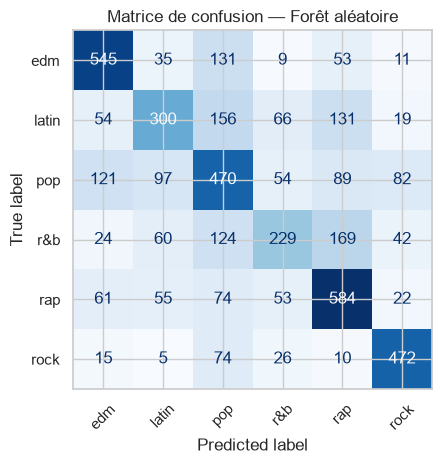

,rappel
rock,78.4%
edm,69.5%
rap,68.8%
pop,51.5%
latin,41.3%
r&b,35.3%


In [14]:
best_classifier_name = max(
    classification_cv_f1, key=classification_cv_f1.get
)
best_classifier = classification_models[best_classifier_name]
best_classification_predictions = classification_predictions[
    best_classifier_name
]
best_classification_row = classification_comparison.loc[
    classification_comparison["model"] == best_classifier_name
].iloc[0]
print(f"Modèle retenu : {best_classifier_name}")
print(f"F1 macro CV : {best_classification_row['f1_macro_cv']:.3f}")
print(f"Accuracy test : {best_classification_row['accuracy_test']:.3f}")
print(f"F1 macro test : {best_classification_row['f1_macro_test']:.3f}")
print(
    classification_report(
        classification_y_test,
        best_classification_predictions,
        labels=genre_labels,
        zero_division=0,
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=classification_confusion_matrices[best_classifier_name],
    display_labels=genre_labels,
).plot(xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title(f"Matrice de confusion — {best_classifier_name}")
plt.tight_layout()
plt.show()

best_confusion_matrix = classification_confusion_matrices[
    best_classifier_name
]
genre_recall = pd.Series(
    np.diag(best_confusion_matrix) / best_confusion_matrix.sum(axis=1),
    index=genre_labels,
    name="rappel",
).sort_values(ascending=False)
display(genre_recall.to_frame().style.format("{:.1%}"))

,genre_reel,genre_predit,edm,latin,pop,r&b,rap,rock
25485,edm,edm,86.4%,4.3%,5.7%,0.3%,3.1%,0.2%
7127,rap,r&b,1.3%,10.5%,11.2%,40.7%,27.3%,9.0%
20183,r&b,rap,3.0%,18.7%,15.1%,22.2%,40.1%,0.8%
8903,rap,rap,2.6%,20.9%,4.8%,15.8%,55.6%,0.3%
13694,rock,rock,17.2%,0.0%,10.9%,1.8%,4.7%,65.4%


,importance
tempo,0.116
speechiness,0.111
release_year,0.104
danceability,0.101
energy,0.093
acousticness,0.084
valence,0.078
loudness,0.070
duration_min,0.069
instrumentalness,0.067


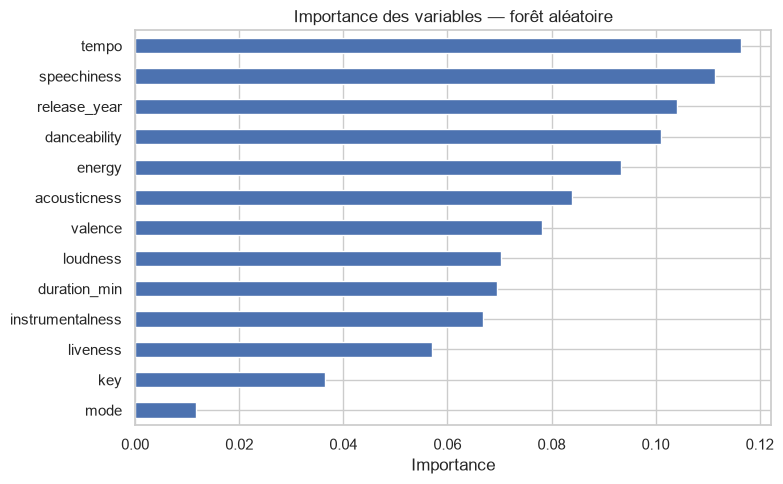

In [15]:
probability_preview_size = 5
classification_probabilities = best_classifier.predict_proba(
    classification_x_test.iloc[:probability_preview_size]
)
probability_preview = pd.DataFrame(
    classification_probabilities,
    columns=best_classifier.classes_,
    index=classification_x_test.index[:probability_preview_size],
)
probability_preview.insert(
    0, "genre_predit",
    best_classification_predictions[:probability_preview_size],
)
probability_preview.insert(
    0,
    "genre_reel",
    classification_y_test.iloc[:probability_preview_size].values,
)
display(
    probability_preview.style.format(
        {genre: "{:.1%}" for genre in best_classifier.classes_}
    )
)

forest_classifier = classification_models["Forêt aléatoire"]
classification_feature_importance = pd.Series(
    forest_classifier.feature_importances_,
    index=classification_features,
    name="importance",
).sort_values(ascending=False)
display(classification_feature_importance.to_frame().style.format("{:.3f}"))
classification_feature_importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Importance des variables — forêt aléatoire")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

,accuracy_train,accuracy_test,precision_macro,recall_macro,f1_macro
0,0.582,0.582,0.579,0.607,0.551


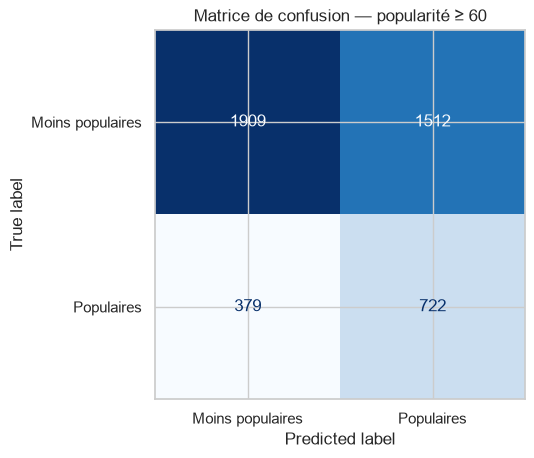

In [16]:
popularity_data = classification_data.dropna(
    subset=["track_popularity"]
).copy()
popularity_y = (popularity_data["track_popularity"] >= 60).astype(int)
(
    popularity_x_train,
    popularity_x_test,
    popularity_y_train,
    popularity_y_test,
) = train_test_split(
    popularity_data[classification_features],
    popularity_y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=popularity_y,
)
popularity_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, class_weight="balanced"),
)
popularity_classifier.fit(popularity_x_train, popularity_y_train)
popularity_train_predictions = popularity_classifier.predict(
    popularity_x_train
)
popularity_test_predictions = popularity_classifier.predict(popularity_x_test)
popularity_classification_metrics = pd.DataFrame(
    [
        {
            "accuracy_train": accuracy_score(
                popularity_y_train, popularity_train_predictions
            ),
            "accuracy_test": accuracy_score(
                popularity_y_test, popularity_test_predictions
            ),
            "precision_macro": precision_score(
                popularity_y_test,
                popularity_test_predictions,
                average="macro",
                zero_division=0,
            ),
            "recall_macro": recall_score(
                popularity_y_test,
                popularity_test_predictions,
                average="macro",
                zero_division=0,
            ),
            "f1_macro": f1_score(
                popularity_y_test,
                popularity_test_predictions,
                average="macro",
                zero_division=0,
            ),
        }
    ]
)
display(popularity_classification_metrics.style.format("{:.3f}"))
ConfusionMatrixDisplay.from_predictions(
    popularity_y_test,
    popularity_test_predictions,
    display_labels=["Moins populaires", "Populaires"],
    cmap="Blues",
    colorbar=False,
)
plt.title("Matrice de confusion — popularité ≥ 60")
plt.show()

## 6. Export des modèles

Les noms d’artefacts ci-dessous sont conservés pour rester compatibles avec les pages de l’application Streamlit. Le modèle d’énergie exporté utilise les 11 variables numériques attendues par ces pages.

In [17]:
joblib.dump(
    best_deployable_regression["estimator"],
    "modele_regression_energie.joblib",
)
joblib.dump(
    best_linear_numeric_regression["estimator"],
    "modele_lineaire_energie.joblib",
)
joblib.dump(best_classifier, "meilleur_modele_spotify.joblib")
joblib.dump(
    regression_numeric_features, "colonnes_numeriques.joblib"
)
joblib.dump(
    regression_x_categorical_train.columns.tolist(),
    "colonnes_categories.joblib",
)

print("Modèles et listes de variables exportés à la racine du projet.")
print(f"Régression énergie : {best_deployable_regression['model']}")
print(f"Classification des genres : {best_classifier_name}")

Modèles et listes de variables exportés à la racine du projet.
Régression énergie : Forêt aléatoire
Classification des genres : Forêt aléatoire
